# Next Month Electricity Bill Prediction — Warangal
**HCLTech Hackathon · Data Science**

This notebook follows the complete industrial ML sequence (20 steps), from business understanding to monitoring.
Files used: `electricity_bills_simple.csv`, `bill_utils.py` (shared feature code), output `bill_model.joblib` (used by `app.py`).

## Step 1 — Business understanding
**Problem:** The electricity distribution company wants to predict each customer's **next month bill (₹)**.

**Why it matters**
- Customers get an early warning of high bills (e.g. before summer) and can reduce usage.
- The utility can plan revenue and spot unusual bills.

**ML task:** Supervised **regression**. Target = `next_month_bill`.

**Success metric:** MAE in ₹ (easy to explain: "on average we are off by ₹X"), also RMSE, R² and MAPE.
We must beat the naive baseline *"next bill = this month's bill"*.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import cross_validate, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.inspection import permutation_importance
from bill_utils import (add_lag_features, FeatureEngineer, TARGET, CAT_ONEHOT, CAT_ORDINAL,
                        HOUSE_ORDER, NUM_COLS, INPUT_COLS)
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

## Step 2 — Data collection
One location (Warangal). 200 customers × 23 months of billing records, with customer details and monthly weather.

In [2]:
df = pd.read_csv("electricity_bills_simple.csv")
print(df.shape)
df.head()

(4600, 14)


,customer_id,area,connection_type,house_type,family_size,num_acs,has_solar,payment_mode,month,avg_temp_c,humidity_pct,units_consumed,bill_amount,next_month_bill
0,C1000,Hanamkonda,Domestic,Independent,4.0,0.0,No,Net Banking,2024-11,24.7,55.7,145.0,552.5,669.5
1,C1000,Hanamkonda,Domestic,Independent,4.0,0.0,No,NaN,2024-12,22.9,59.6,171.0,669.5,678.5
2,C1000,Hanamkonda,Domestic,Independent,4.0,0.0,No,Net Banking,2025-01,24.9,57.6,173.0,678.5,642.5
3,C1000,Hanamkonda,Domestic,NaN,4.0,0.0,No,Net Banking,2025-02,27.7,44.8,165.0,642.5,678.5
4,C1000,Hanamkonda,Domestic,Independent,4.0,0.0,No,Net Banking,2025-03,29.4,37.9,173.0,678.5,777.5


## Step 3 — Data validation
Check data types, missing values, duplicates, valid ranges and that every customer has a continuous monthly history.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customer_id      4600 non-null   object 
 1   area             4600 non-null   object 
 2   connection_type  4600 non-null   object 
 3   house_type       4374 non-null   object 
 4   family_size      4338 non-null   float64
 5   num_acs          4378 non-null   float64
 6   has_solar        4600 non-null   object 
 7   payment_mode     4359 non-null   object 
 8   month            4600 non-null   object 
 9   avg_temp_c       4386 non-null   float64
 10  humidity_pct     4376 non-null   float64
 11  units_consumed   4370 non-null   float64
 12  bill_amount      4600 non-null   float64
 13  next_month_bill  4600 non-null   float64
dtypes: float64(7), object(7)
memory usage: 503.3+ KB


In [4]:
print("Missing values per column:\n", df.isna().sum()[df.isna().sum() > 0], "\n")
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate (customer, month):", df.duplicated(["customer_id", "month"]).sum())
print("Months per customer:", df.groupby("customer_id").month.nunique().describe()[["min", "max"]].to_dict())
print("Month range:", df.month.min(), "->", df.month.max())

# business-rule range checks
checks = {
    "bill_amount > 0": (df.bill_amount > 0).all(),
    "next_month_bill > 0": (df.next_month_bill > 0).all(),
    "family_size 1-10": df.family_size.dropna().between(1, 10).all(),
    "num_acs 0-6": df.num_acs.dropna().between(0, 6).all(),
    "avg_temp 10-45 C": df.avg_temp_c.dropna().between(10, 45).all(),
    "humidity 0-100 %": df.humidity_pct.dropna().between(0, 100).all(),
}
print("\nRange checks:", checks)

Missing values per column:
 house_type        226
family_size       262
num_acs           222
payment_mode      241
avg_temp_c        214
humidity_pct      224
units_consumed    230
dtype: int64 

Duplicate rows: 0
Duplicate (customer, month): 0
Months per customer: {'min': 23.0, 'max': 23.0}
Month range: 2024-11 -> 2026-09

Range checks: {'bill_amount > 0': np.True_, 'next_month_bill > 0': np.True_, 'family_size 1-10': np.True_, 'num_acs 0-6': np.True_, 'avg_temp 10-45 C': np.True_, 'humidity 0-100 %': np.True_}


In [5]:
for c in ["area", "connection_type", "house_type", "has_solar", "payment_mode"]:
    print(c, "->", df[c].value_counts(dropna=False).to_dict())

area -> {'Kazipet': 1219, 'Subedari': 1173, 'Warangal Fort': 1150, 'Hanamkonda': 1058}
connection_type -> {'Domestic': 3703, 'Commercial': 897}
house_type -> {'1BHK': 1487, '2BHK': 1371, '3BHK': 840, 'Independent': 676, nan: 226}
has_solar -> {'No': 3864, 'Yes': 736}
payment_mode -> {'UPI': 1936, 'Cash': 1007, 'Net Banking': 915, 'Card': 501, nan: 241}


## Step 4 — Initial EDA

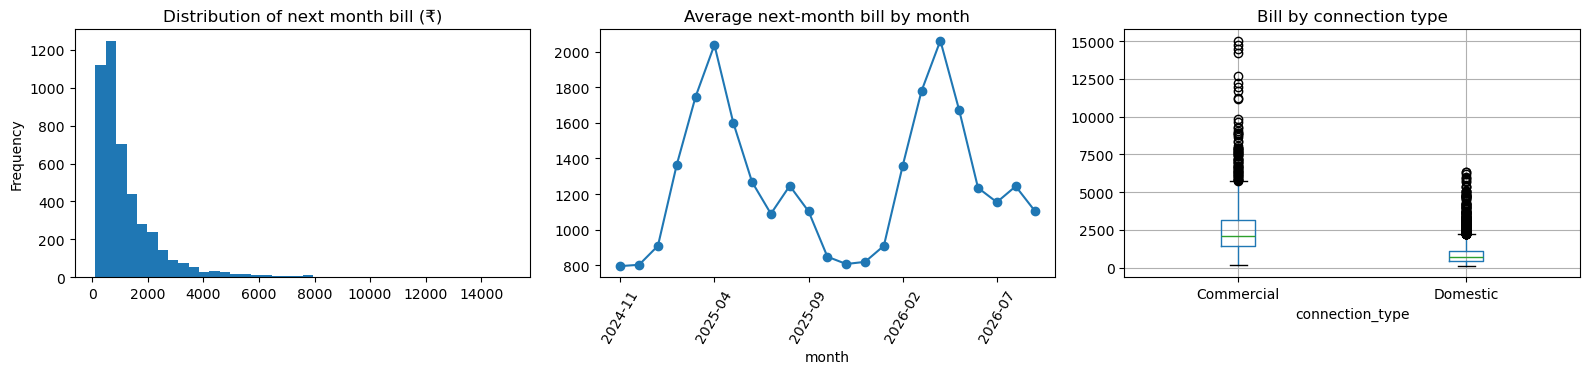

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df[TARGET].plot.hist(bins=40, ax=ax[0], title="Distribution of next month bill (₹)")
df.groupby("month")[TARGET].mean().plot(ax=ax[1], marker="o", title="Average next-month bill by month")
ax[1].tick_params(axis="x", rotation=60)
df.boxplot(column="bill_amount", by="connection_type", ax=ax[2]); ax[2].set_title("Bill by connection type")
plt.suptitle(""); plt.tight_layout(); plt.show()

In [7]:
print(df.groupby(["connection_type", "has_solar"]).bill_amount.median().round(0))
print(df.groupby("house_type").bill_amount.median().round(0))
print(df.groupby("payment_mode").bill_amount.median().round(0))

connection_type  has_solar
Commercial       No           2327.0
                 Yes           801.0
Domestic         No            764.0
                 Yes           308.0
Name: bill_amount, dtype: float64
house_type
1BHK            696.0
2BHK            824.0
3BHK           1106.0
Independent     806.0
Name: bill_amount, dtype: float64
payment_mode
Card           872.0
Cash           620.0
Net Banking    836.0
UPI            914.0
Name: bill_amount, dtype: float64


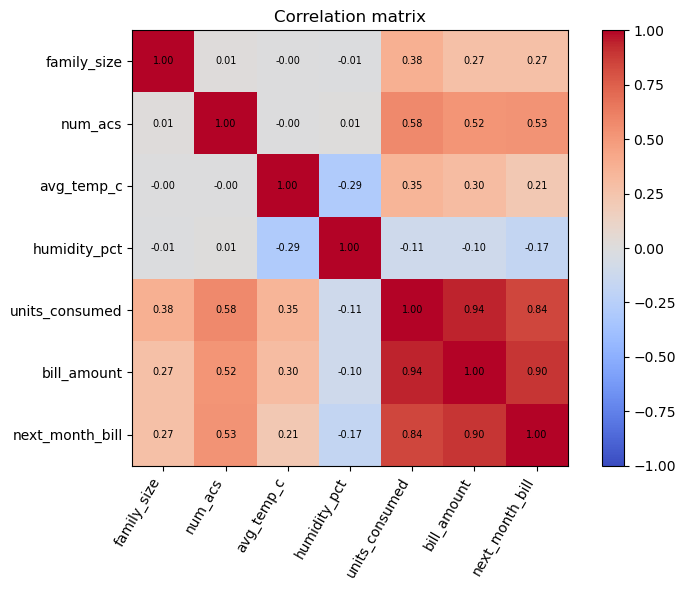

In [8]:
num = df.select_dtypes("number")
corr = num.corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); plt.title("Correlation matrix"); plt.tight_layout(); plt.show()

**EDA findings**
- Target is right-skewed (a few large commercial bills).
- Clear seasonality: bills peak in April–May (AC usage) and dip in winter.
- Commercial connections pay ~3× more; rooftop solar cuts the bill by more than half.
- `payment_mode` shows no relationship with the bill → candidate to drop.
- `bill_amount` and `units_consumed` correlate strongly with the target.

## Step 5 — Target and feature identification
- **Target:** `next_month_bill`
- **Drop:** `customer_id` (identifier), `payment_mode` (no signal — confirmed in Step 11)
- **Categorical:** `area`, `connection_type`, `has_solar` (one-hot), `house_type` (ordinal: 1BHK < 2BHK < 3BHK < Independent)
- **Numeric:** family size, ACs, temperature, humidity, units, current bill

**History (lag) features** are created here, *before* the split, because they need each customer's full timeline.
They only use **past** months, so there is no leakage.

In [9]:
df = add_lag_features(df)
df[["customer_id", "month", "bill_amount", "prev_bill", "rolling_3m_bill", "bill_change", TARGET]].head(6)

,customer_id,month,bill_amount,prev_bill,rolling_3m_bill,bill_change,next_month_bill
0,C1000,2024-11,552.5,NaN,552.5,NaN,669.5
1,C1000,2024-12,669.5,552.5,611.0,117.0,678.5
2,C1000,2025-01,678.5,669.5,633.5,9.0,642.5
3,C1000,2025-02,642.5,678.5,663.5,-36.0,678.5
4,C1000,2025-03,678.5,642.5,666.5,36.0,777.5
5,C1000,2025-04,777.5,678.5,699.5,99.0,701.0


## Step 6 — Train / validation / test split (time-based)
Random splitting would let the model "see the future". We split by **month**:
- Train: Nov 2024 – Mar 2026 · Validation: Apr – Jun 2026 · Test: Jul – Sep 2026

In [10]:
train = df[df.month <= "2026-03"].sort_values(["month", "customer_id"])
val   = df[(df.month >= "2026-04") & (df.month <= "2026-06")]
test  = df[df.month >= "2026-07"]
X_train, y_train = train[INPUT_COLS], train[TARGET]
X_val,   y_val   = val[INPUT_COLS],   val[TARGET]
X_test,  y_test  = test[INPUT_COLS],  test[TARGET]
print(f"Train {X_train.shape}  Val {X_val.shape}  Test {X_test.shape}")

Train (3400, 14)  Val (600, 14)  Test (600, 14)


## Steps 7–11 — Preprocessing & feature engineering (fitted on TRAIN only)
All steps are put inside one sklearn `Pipeline`, so `fit` learns medians / categories / means **only from training data**
and the exact same transformations are applied to validation, test and the Streamlit app.

> Order note: in code the feature-engineering transformer runs first, because new features are built from raw columns;
> any NaN it produces (e.g. units ÷ missing family size) is then filled by the imputer.

## Step 7 — Missing value imputation
- Numeric → **median** (robust to the skewed bills / outliers)
- Categorical → **most frequent** value

In [11]:
print("Missing in TRAIN before imputation:\n", X_train.isna().sum()[X_train.isna().sum() > 0])
num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")
num_imputer.fit(X_train[["family_size", "num_acs", "avg_temp_c", "humidity_pct", "units_consumed"]])
print("\nMedians learned from train:", dict(zip(num_imputer.feature_names_in_, num_imputer.statistics_)))

Missing in TRAIN before imputation:
 house_type        167
family_size       185
num_acs           158
avg_temp_c        170
humidity_pct      153
units_consumed    167
prev_bill         200
bill_change       200
dtype: int64

Medians learned from train: {'family_size': np.float64(4.0), 'num_acs': np.float64(1.0), 'avg_temp_c': np.float64(26.4), 'humidity_pct': np.float64(56.5), 'units_consumed': np.float64(185.0)}


## Step 8 — Encoding categorical variables
- `area`, `connection_type`, `has_solar` → **One-Hot** (no natural order). `handle_unknown="ignore"` protects the app from unseen values.
- `house_type` → **Ordinal** (has a natural size order).

In [12]:
onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ordinal = OrdinalEncoder(categories=HOUSE_ORDER, handle_unknown="use_encoded_value", unknown_value=-1)
demo = onehot.fit(X_train[CAT_ONEHOT].fillna("missing"))
print("One-hot columns:", list(onehot.get_feature_names_out()))

One-hot columns: ['area_Hanamkonda', 'area_Kazipet', 'area_Subedari', 'area_Warangal Fort', 'connection_type_Commercial', 'connection_type_Domestic', 'has_solar_No', 'has_solar_Yes']


## Step 9 — Feature scaling
Features are on very different scales (temperature ≈ 30, units ≈ hundreds, bills ≈ thousands).
**StandardScaler** (mean 0, std 1) is needed for linear models; tree models are unaffected but it does no harm.

In [13]:
print(X_train[["avg_temp_c", "units_consumed", "bill_amount"]].describe().loc[["mean", "std"]].round(1))

      avg_temp_c  units_consumed  bill_amount
mean        26.7           207.2       1148.9
std          3.6           137.5       1207.6


## Step 10 — Feature engineering
| Feature | Formula | Why |
|---|---|---|
| `prev_bill`, `rolling_3m_bill`, `bill_change` | lags (Step 5) | recent history & trend |
| `next_month_sin/cos` | cyclic encoding of the month being predicted | seasonality; Dec is close to Jan |
| `next_is_summer` | next month in Mar–May | AC season jump |
| `units_per_person` | units / family size | usage intensity |
| `ac_x_temp` | ACs × temperature | AC load grows with heat |

In [14]:
fe = FeatureEngineer()
fe.transform(X_train.head())[["month", "next_month_sin", "next_month_cos", "next_is_summer",
                              "units_per_person", "ac_x_temp"]]

,month,next_month_sin,next_month_cos,next_is_summer,units_per_person,ac_x_temp
0,2024-11,-2.449294e-16,1.0,0,36.25,0.0
23,2024-11,-2.449294e-16,1.0,0,55.60,23.8
46,2024-11,-2.449294e-16,1.0,0,44.80,0.0
69,2024-11,-2.449294e-16,1.0,0,102.00,73.8
92,2024-11,-2.449294e-16,1.0,0,68.20,48.0


In [15]:
# Assemble the full preprocessing pipeline (Steps 7-10)
numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
onehot_pipe  = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                         ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
ordinal_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                         ("encode", OrdinalEncoder(categories=HOUSE_ORDER,
                                                   handle_unknown="use_encoded_value", unknown_value=-1)),
                         ("scale", StandardScaler())])

def make_preprocessor():
    ct = ColumnTransformer([("num", numeric_pipe, NUM_COLS),
                            ("ohe", onehot_pipe, CAT_ONEHOT),
                            ("ord", ordinal_pipe, CAT_ORDINAL)], remainder="drop")
    return Pipeline([("features", FeatureEngineer()), ("prep", ct)])

prep = make_preprocessor().fit(X_train)
Xt_train = pd.DataFrame(prep.transform(X_train), columns=prep[-1].get_feature_names_out())
print("Shape after preprocessing:", Xt_train.shape, "| any NaN left?", Xt_train.isna().any().any())
Xt_train.describe().loc[["mean", "std"]].round(2)

Shape after preprocessing: (3400, 23) | any NaN left? False


,num__family_size,num__num_acs,num__avg_temp_c,num__humidity_pct,num__units_consumed,num__bill_amount,num__prev_bill,num__rolling_3m_bill,num__bill_change,num__next_month_sin,num__next_month_cos,num__next_is_summer,num__units_per_person,num__ac_x_temp,ohe__area_Hanamkonda,ohe__area_Kazipet,ohe__area_Subedari,ohe__area_Warangal Fort,ohe__connection_type_Commercial,ohe__connection_type_Domestic,ohe__has_solar_No,ohe__has_solar_Yes,ord__house_type
mean,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.23,0.26,0.26,0.25,0.2,0.8,0.84,0.16,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.42,0.44,0.44,0.43,0.4,0.4,0.37,0.37,1.0


## Step 11 — Feature selection
Mutual information measures how much each feature tells us about the target (captures non-linear links too).
We also confirm `payment_mode` carries no signal before dropping it.

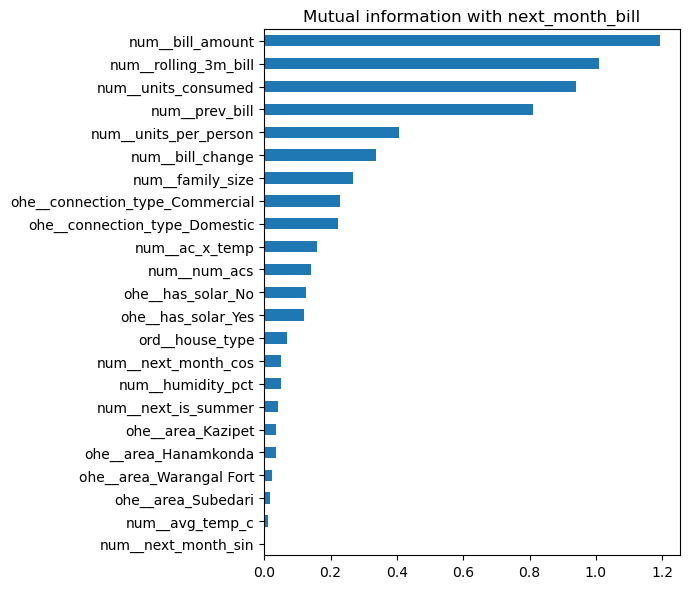

payment_mode MI: {'Card': np.float64(0.02), 'Cash': np.float64(0.024), 'Net Banking': np.float64(0.015), 'UPI': np.float64(0.022), 'missing': np.float64(0.0)} -> ~0, so it is dropped


In [16]:
mi = pd.Series(mutual_info_regression(Xt_train, y_train, random_state=RANDOM_STATE),
               index=Xt_train.columns).sort_values()
mi.plot.barh(figsize=(7, 6), title="Mutual information with next_month_bill"); plt.tight_layout(); plt.show()

# payment_mode check (one-hot, train only)
pm = pd.get_dummies(train.payment_mode.fillna("missing"))
pm_mi = mutual_info_regression(pm, y_train, discrete_features=True, random_state=RANDOM_STATE)
print("payment_mode MI:", dict(zip(pm.columns, pm_mi.round(3))), "-> ~0, so it is dropped")

**Decision:** keep all engineered features (each has non-zero MI and a clear business reason); drop `payment_mode` and `customer_id`.

## Step 12 — Model training
Start with a **naive baseline** and a **Linear Regression**, then try stronger models.

In [17]:
def evaluate(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred),
            "MAPE_%": 100 * mean_absolute_percentage_error(y_true, y_pred)}

def make_model(estimator):
    return Pipeline([("prep", make_preprocessor()), ("model", estimator)])

print("Naive baseline (next = current bill):", {k: round(v, 3) for k, v in evaluate(y_val, X_val.bill_amount).items()})
lr = make_model(LinearRegression()).fit(X_train, y_train)
print("Linear Regression:                  ", {k: round(v, 3) for k, v in evaluate(y_val, lr.predict(X_val)).items()})

Naive baseline (next = current bill): {'MAE': 442.205, 'RMSE': np.float64(808.809), 'R2': 0.79, 'MAPE_%': 26.115}
Linear Regression:                   {'MAE': 375.051, 'RMSE': np.float64(601.605), 'R2': 0.884, 'MAPE_%': 38.736}


## Step 13 — Cross-validation (time-series folds)
Expanding-window folds on the training months: train on earlier months, validate on the next 2 months.

In [18]:
def time_folds(months, n_folds=4, val_months=2):
    """Expanding-window CV: each fold validates on later months than it trains on."""
    months = months.reset_index(drop=True)
    uniq = sorted(months.unique())
    folds = []
    for k in range(n_folds, 0, -1):
        cut = len(uniq) - k * val_months
        tr = months.index[months.isin(uniq[:cut])].values
        va = months.index[months.isin(uniq[cut:cut + val_months])].values
        folds.append((tr, va))
    return folds

X_train = X_train.reset_index(drop=True); y_train = y_train.reset_index(drop=True)
cv = time_folds(X_train.month)

candidates = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}
cv_rows = []
for name, est in candidates.items():
    s = cross_validate(make_model(est), X_train, y_train, cv=cv,
                       scoring=["neg_mean_absolute_error", "r2"])
    cv_rows.append({"model": name, "CV_MAE": -s["test_neg_mean_absolute_error"].mean(),
                    "CV_MAE_std": s["test_neg_mean_absolute_error"].std(), "CV_R2": s["test_r2"].mean()})
cv_results = pd.DataFrame(cv_rows).sort_values("CV_MAE").round(3)
cv_results

,model,CV_MAE,CV_MAE_std,CV_R2
3,Gradient Boosting,204.859,54.606,0.823
2,Random Forest,207.640,60.708,0.842
0,Linear Regression,300.076,95.066,0.767
1,Ridge,300.201,95.373,0.768


## Step 14 — Hyperparameter tuning
RandomizedSearchCV with the same time-series folds, for the two tree models.

In [19]:
search_spaces = {
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [None, 8, 12, 16],
        "model__min_samples_leaf": [1, 2, 4, 8],
        "model__max_features": [0.5, 0.7, 1.0]}),
    "Gradient Boosting": (HistGradientBoostingRegressor(random_state=RANDOM_STATE), {
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_iter": [200, 400, 600],
        "model__max_depth": [None, 4, 6, 8],
        "model__min_samples_leaf": [10, 20, 40],
        "model__l2_regularization": [0.0, 0.1, 1.0]}),
}
tuned = {}
for name, (est, grid) in search_spaces.items():
    rs = RandomizedSearchCV(make_model(est), grid, n_iter=12, cv=cv, scoring="neg_mean_absolute_error",
                            random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
    tuned[name] = rs.best_estimator_
    print(f"{name}: best CV MAE = {-rs.best_score_:.2f}  params = {rs.best_params_}")

Random Forest: best CV MAE = 207.37  params = {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': 16}
Gradient Boosting: best CV MAE = 196.02  params = {'model__min_samples_leaf': 20, 'model__max_iter': 600, 'model__max_depth': 4, 'model__learning_rate': 0.1, 'model__l2_regularization': 0.1}


## Step 15 — Model comparison (on the validation set)

In [20]:
final_candidates = {"Naive baseline": None,
                    "Linear Regression": make_model(LinearRegression()).fit(X_train, y_train),
                    "Ridge": make_model(Ridge(alpha=1.0)).fit(X_train, y_train),
                    **{f"{k} (tuned)": v for k, v in tuned.items()}}
rows = []
for name, m in final_candidates.items():
    pred = X_val.bill_amount if m is None else m.predict(X_val)
    rows.append({"model": name, **evaluate(y_val, pred)})
comparison = pd.DataFrame(rows).sort_values("MAE").round(3)
display(comparison)
best_name = comparison[comparison.model != "Naive baseline"].iloc[0].model
best_model = final_candidates[best_name]
print("Selected model:", best_name)

,model,MAE,RMSE,R2,MAPE_%
4,Gradient Boosting (tuned),254.058,428.066,0.941,18.561
3,Random Forest (tuned),265.217,469.980,0.929,17.520
1,Linear Regression,375.051,601.605,0.884,38.736
2,Ridge,375.191,601.929,0.884,38.730
0,Naive baseline,442.205,808.809,0.790,26.115


Selected model: Gradient Boosting (tuned)


## Step 16 — Final test evaluation
The test months (Jul–Sep 2026) were never used for training, tuning or model choice.
The selected model is refit on train + validation, then scored once on test.

TEST: {'MAE': 179.761, 'RMSE': np.float64(304.006), 'R2': 0.917, 'MAPE_%': 16.004}
Naive baseline on TEST: {'MAE': 219.942, 'RMSE': np.float64(405.912), 'R2': 0.852, 'MAPE_%': 18.708}


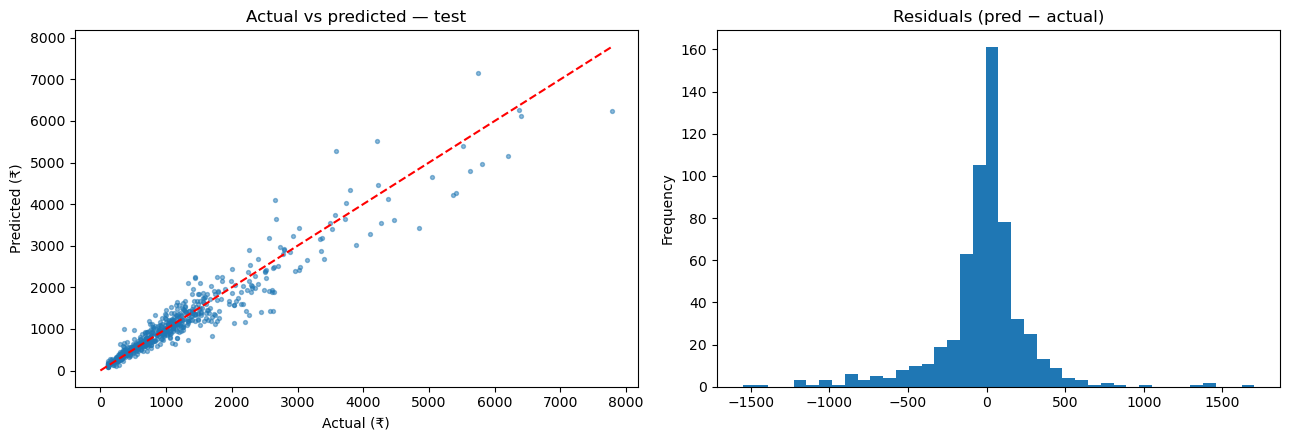

In [21]:
X_trval = pd.concat([X_train, X_val]); y_trval = pd.concat([y_train, y_val])
best_model.fit(X_trval, y_trval)
test_pred = best_model.predict(X_test)
test_metrics = evaluate(y_test, test_pred)
print("TEST:", {k: round(v, 3) for k, v in test_metrics.items()})
print("Naive baseline on TEST:", {k: round(v, 3) for k, v in evaluate(y_test, X_test.bill_amount).items()})

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(y_test, test_pred, s=8, alpha=.5)
lim = [0, max(y_test.max(), test_pred.max())]; ax[0].plot(lim, lim, "r--")
ax[0].set(xlabel="Actual (₹)", ylabel="Predicted (₹)", title="Actual vs predicted — test")
(test_pred - y_test).plot.hist(bins=40, ax=ax[1], title="Residuals (pred − actual)")
plt.tight_layout(); plt.show()

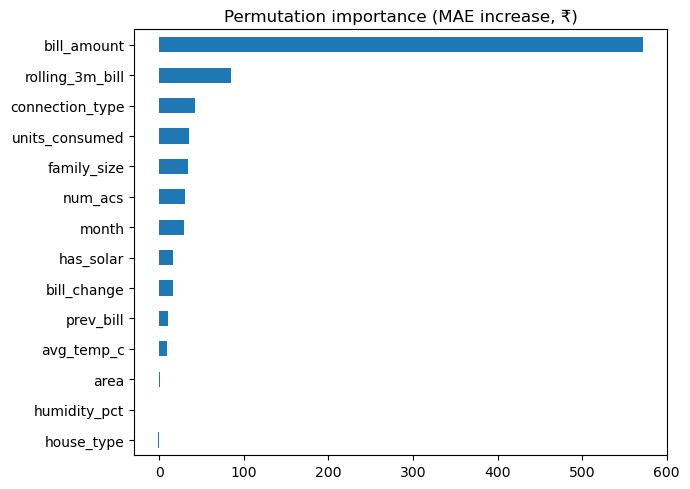

In [22]:
pi = permutation_importance(best_model, X_test, y_test, scoring="neg_mean_absolute_error",
                            n_repeats=5, random_state=RANDOM_STATE)
importance = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
importance.plot.barh(figsize=(7, 5), title="Permutation importance (MAE increase, ₹)"); plt.tight_layout(); plt.show()

## Step 17 — Final model retraining
Performance is confirmed, so we retrain on **all** labelled months (train + val + test) to use the most recent data for deployment.

In [23]:
X_all, y_all = df[INPUT_COLS], df[TARGET]
final_model = best_model.fit(X_all, y_all)
print("Final model trained on", len(X_all), "rows")

Final model trained on 4600 rows


## Step 18 — Model serialization
Save the whole pipeline (preprocessing + model) plus metadata for the app.

In [24]:
artifact = {
    "model": final_model,
    "model_name": best_name,
    "input_cols": INPUT_COLS,
    "test_metrics": test_metrics,
    "comparison": comparison,
    "cv_results": cv_results,
    "importance": importance,
    "test_results": pd.DataFrame({"month": X_test.month.values, "actual": y_test.values, "predicted": test_pred}),
    "train_stats": X_trval[["avg_temp_c", "units_consumed", "bill_amount"]].describe().loc[["mean", "std"]],
    "trained_on": f"{df.month.min()} to {df.month.max()}",
}
joblib.dump(artifact, "bill_model.joblib")
loaded = joblib.load("bill_model.joblib")
print("Saved & reloaded. Sample prediction:", loaded["model"].predict(X_test.head(1)).round(2))

Saved & reloaded. Sample prediction: [622.36]


## Step 19 — Deployment
`app.py` is a Streamlit app that loads `bill_model.joblib` and offers:
1. **Existing customer** — pick a customer, see their bill history and next-month prediction.
2. **New customer / what-if** — enter details manually.
3. **Batch prediction** — upload a CSV, download predictions.
4. **Model performance** — metrics, comparison, test plot and feature importance.

Run it with:
```
pip install -r requirements.txt
streamlit run app.py
```

In [25]:
# What the app does for one customer:
latest = df[df.customer_id == "C1000"].sort_values("month").tail(1)
print("Current bill:", latest.bill_amount.item(), "| Predicted next bill:", final_model.predict(latest[INPUT_COLS]).round(2))

Current bill: 687.5 | Predicted next bill: [648.96]


## Step 20 — Monitoring and maintenance
After deployment, track:
- **Prediction error** each month once actual bills arrive (alert if MAE rises > 20% over the test MAE).
- **Data drift** — compare incoming feature distributions with training (PSI below).
- **Retraining** — monthly, or whenever drift / error alerts fire; also after tariff changes.

In [26]:
res = artifact["test_results"].assign(abs_err=lambda d: (d.actual - d.predicted).abs())
print("MAE by month on test:\n", res.groupby("month").abs_err.mean().round(2))

def psi(expected, actual, bins=10):
    """Population Stability Index: <0.1 stable, 0.1-0.25 moderate drift, >0.25 major drift."""
    expected, actual = expected.dropna(), actual.dropna()
    cuts = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    e = np.histogram(expected, cuts)[0] / len(expected) + 1e-6
    a = np.histogram(actual.clip(cuts[0], cuts[-1]), cuts)[0] / len(actual) + 1e-6
    return float(np.sum((a - e) * np.log(a / e)))

drift = {c: round(psi(X_train[c], X_test[c]), 3) for c in ["avg_temp_c", "humidity_pct", "units_consumed", "bill_amount"]}
print("\nPSI train vs test:", drift)

MAE by month on test:
 month
2026-07    169.85
2026-08    188.92
2026-09    180.51
Name: abs_err, dtype: float64

PSI train vs test: {'avg_temp_c': 5.647, 'humidity_pct': 9.299, 'units_consumed': 0.046, 'bill_amount': 0.042}


Temperature/humidity drift between training and test months is expected (seasons), which is why seasonality features are in the model.
In production, PSI would be compared month-to-month against the same month last year.

---
### Summary
- Time-based split prevents leakage; all preprocessing is fitted on training data only inside a Pipeline.
- Engineered history + seasonality features drive the predictions.
- The tuned tree model clearly beats the naive baseline and linear models; it is saved and served via Streamlit.